# Same pixels, new picture

Generate an image from a text prompt whose color histogram is **identical** to a source image's. Since the output is the same size, that means it's literally a rearrangement of the source's pixels.

**How it works**

1. Sample from Stable Diffusion 3.5 Medium (a rectified-flow model) with a custom loop.
2. In the middle of sampling, take the model's prediction of the final image, pull its colors onto the source's color distribution (*sliced optimal transport*), and put it back on the same noise trajectory. The model then has the remaining steps to make the color-corrected image look natural.
3. At the end, an exact snap assigns every output pixel a distinct source pixel, so the histogram matches bit for bit.

**Before running**

- *Runtime → Change runtime type → GPU.* A T4 works at 512×512.
- Accept the license at [huggingface.co/stabilityai/stable-diffusion-3.5-medium](https://huggingface.co/stabilityai/stable-diffusion-3.5-medium) and have a Hugging Face access token ready.

In [ ]:
!pip install -q -U diffusers transformers accelerate sentencepiece protobuf imageio-ffmpeg

In [ ]:
from huggingface_hub import notebook_login
notebook_login()

## Load the model

In [ ]:
import torch, numpy as np
from diffusers import StableDiffusion3Pipeline

device = "cuda"
# bf16 needs an Ampere-or-newer GPU (L4, A100). A T4 falls back to fp16.
dtype = torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16

# Skipping the T5 text encoder saves ~9GB of GPU memory. Prompts still work
# through SD3's two CLIP encoders, just with a bit less prompt adherence.
pipe = StableDiffusion3Pipeline.from_pretrained(
    "stabilityai/stable-diffusion-3.5-medium",
    text_encoder_3=None, tokenizer_3=None, torch_dtype=dtype,
).to(device)
vae = pipe.vae

## Settings

In [ ]:
SIZE = 512                                              # output is SIZE x SIZE
PROMPT = "a snowy mountain range at dawn, photograph"   # what to draw
SOURCE_PROMPT = "a tropical beach at sunset, photograph" # source image, if you don't upload one
STEPS = 28
CFG = 4.5
SEED = 0

## Source image

The pixels you're allowed to use. Upload your own, or generate one.

In [ ]:
from PIL import Image, ImageOps

UPLOAD = False   # True: upload your own image. False: generate one from SOURCE_PROMPT.

if UPLOAD:
    from google.colab import files
    name = next(iter(files.upload()))
    source = Image.open(name).convert("RGB")
else:
    source = pipe(SOURCE_PROMPT, height=SIZE, width=SIZE, num_inference_steps=STEPS,
                  guidance_scale=CFG, generator=torch.Generator(device).manual_seed(123)).images[0]

source = ImageOps.fit(source, (SIZE, SIZE))   # center-crop so pixel counts match
src8 = np.asarray(source)                     # (H, W, 3) uint8
src = torch.tensor(src8, device=device, dtype=torch.float32).reshape(-1, 3) / 255
source

## Helpers

- `decode` / `encode` convert between SD3's latent space and pixels. The histogram lives in pixel space, so every projection is a round trip.
- `sliced_ot` is the projection: rotate RGB space randomly, match each axis exactly by sorting, rotate back, repeat. Each pixel keeps its *rank* along a direction but takes the source's value at that rank.

In [ ]:
def decode(lat):
    # latents -> image in [0, 1], shape (1, 3, H, W)
    lat = lat / vae.config.scaling_factor + vae.config.shift_factor
    return ((vae.decode(lat.to(vae.dtype)).sample.float() + 1) / 2).clamp(0, 1)

def encode(img):
    # image in [0, 1], shape (1, 3, H, W) -> latents
    lat = vae.encode((img * 2 - 1).to(vae.dtype)).latent_dist.mean
    return (lat - vae.config.shift_factor) * vae.config.scaling_factor

def to_pixels(img):    # (1, 3, H, W) -> (H*W, 3)
    return img[0].permute(1, 2, 0).reshape(-1, 3)

def from_pixels(px):   # (H*W, 3) -> (1, 3, H, W)
    return px.reshape(SIZE, SIZE, 3).permute(2, 0, 1)[None]

def to_uint8(img):     # (1, 3, H, W) in [0, 1] -> (H, W, 3) uint8
    return (img[0].permute(1, 2, 0).cpu().numpy() * 255).round().astype(np.uint8)

def sliced_ot(x, src, iters=30):
    # Move x's color distribution onto src's. x, src: (n, 3) float tensors.
    x = x.clone()
    for _ in range(iters):
        Q, _ = torch.linalg.qr(torch.randn(3, 3, device=x.device))   # random rotation of RGB space
        xp, sp = x @ Q, src @ Q
        for k in range(3):
            order = xp[:, k].argsort()
            xp[order, k] = sp[:, k].sort().values   # i-th smallest takes src's i-th smallest
        x = xp @ Q.T
    return x

## Exact snap

Makes the output literally a permutation of the source's pixels:

1. Pixels whose color exists in the source (and hasn't been used up) take that exact pixel, with zero change.
2. The leftovers are paired by sorting both sets along a 3D Hilbert curve through color space, which keeps nearby colors nearby.

In [ ]:
def color_keys(c):
    c = c.astype(np.int64)
    return (c[:, 0] << 16) | (c[:, 1] << 8) | c[:, 2]

def hilbert(c, bits=8):
    # Position of each RGB color along a 3D Hilbert curve (Skilling's algorithm, vectorized).
    X = [c[:, i].astype(np.int64).copy() for i in range(3)]
    M = 1 << (bits - 1); Q = M
    while Q > 1:
        P = Q - 1
        for i in range(3):
            m = (X[i] & Q) != 0
            X[0] = np.where(m, X[0] ^ P, X[0])
            t = np.where(m, 0, (X[0] ^ X[i]) & P)
            X[0] ^= t; X[i] ^= t
        Q >>= 1
    for i in range(1, 3): X[i] ^= X[i - 1]
    t = np.zeros_like(X[0]); Q = M
    while Q > 1:
        t = np.where((X[2] & Q) != 0, t ^ (Q - 1), t); Q >>= 1
    for i in range(3): X[i] ^= t
    key = np.zeros(len(c), np.int64)
    for b in range(bits - 1, -1, -1):
        for i in range(3):
            key = (key << 1) | ((X[i] >> b) & 1)
    return key

def occurrence_ids(k):
    # Unique id per pixel: (color, how many times that color appeared before it).
    n = len(k); order = np.argsort(k, kind="stable"); ks = k[order]
    starts = np.r_[0, np.flatnonzero(np.diff(ks)) + 1]
    counts = np.diff(np.r_[starts, n])
    rank = np.empty(n, np.int64); rank[order] = np.arange(n) - np.repeat(starts, counts)
    return k * n + rank

def exact_snap(img, src):
    # Rearrange src's pixels to look as much like img as possible. Both (H, W, 3) uint8.
    x, s = img.reshape(-1, 3), src.reshape(-1, 3); n = len(s)
    ix, is_ = occurrence_ids(color_keys(x)), occurrence_ids(color_keys(s))
    s_order = np.argsort(is_); s_sorted = is_[s_order]
    pos = np.minimum(np.searchsorted(s_sorted, ix), n - 1)
    hit = s_sorted[pos] == ix
    perm = np.full(n, -1); perm[hit] = s_order[pos[hit]]
    used = np.zeros(n, bool); used[perm[hit]] = True
    lx, ls = np.flatnonzero(~hit), np.flatnonzero(~used)
    perm[lx[np.argsort(hilbert(x[lx]))]] = ls[np.argsort(hilbert(s[ls]))]
    return s[perm].reshape(src.shape), hit.mean()

def same_histogram(a, b):
    return np.array_equal(np.sort(color_keys(a.reshape(-1, 3))), np.sort(color_keys(b.reshape(-1, 3))))

## The sampling loop

`diffusers` runs time from noise (σ = 1) to image (σ = 0), with `x_t = (1 − σ)·image + σ·noise`. The model predicts the velocity `v = noise − image`, so at every step we can recover both ends of the path:

```
predicted image  x̂₀    = x_t − σ·v
starting noise   noise = x_t + (1 − σ)·v
```

The projection replaces `x̂₀` with its color-corrected version and rebuilds `x_t` from the same noise. It only runs inside `window`: too early and `x̂₀` is a blurry average, too late and the model has no steps left to make the corrected image look natural.

In [ ]:
@torch.no_grad()
def generate(prompt, project=True, project_every=3, window=(0.15, 0.9), seed=SEED, frames=None):
    # frames: optional list that collects (step, sigma, projected?, guess of the final image)
    pe, npe, ppe, nppe = pipe.encode_prompt(prompt, prompt, prompt, device=device)
    cond, pooled = torch.cat([npe, pe]), torch.cat([nppe, ppe])
    pipe.scheduler.set_timesteps(STEPS, device=device)
    sig = pipe.scheduler.sigmas
    c, f = pipe.transformer.config.in_channels, pipe.vae_scale_factor
    lat = torch.randn(1, c, SIZE // f, SIZE // f, device=device, dtype=dtype,
                      generator=torch.Generator(device).manual_seed(seed))

    for i, t in enumerate(pipe.scheduler.timesteps):
        out = pipe.transformer(hidden_states=torch.cat([lat] * 2), timestep=t.expand(2),
                               encoder_hidden_states=cond, pooled_projections=pooled,
                               return_dict=False)[0]
        vu, vc = out.chunk(2)
        v = vu + CFG * (vc - vu)                 # classifier-free guidance
        s = sig[i]
        if frames is not None:
            frames.append((i, float(s), False, to_uint8(decode(lat - s * v))))

        if project and i % project_every == 0 and window[0] < s < window[1]:
            x0 = lat - s * v                     # where we're headed
            noise = lat + (1 - s) * v            # where we came from
            px = sliced_ot(to_pixels(decode(x0)), src).clamp(0, 1)
            x0 = encode(from_pixels(px)).to(dtype)
            lat = ((1 - s) * x0 + s * noise).to(dtype)   # same noise, corrected target
            v = noise - x0
            if frames is not None:
                frames.append((i, float(s), True, to_uint8(decode(x0))))

        lat = (lat + (sig[i + 1] - s) * v).to(dtype)     # Euler step
    return decode(lat)

## Run it

Same prompt and seed, with and without projection, then both snapped to the source's exact pixels.

In [ ]:
baseline = to_uint8(generate(PROMPT, project=False))
projected = to_uint8(generate(PROMPT, project=True))
baseline_snap, b_exact = exact_snap(baseline, src8)
projected_snap, p_exact = exact_snap(projected, src8)

for name, before, after, exact in [("no projection", baseline, baseline_snap, b_exact),
                                   ("projection", projected, projected_snap, p_exact)]:
    change = np.abs(after.astype(int) - before.astype(int)).mean()
    print(f"{name:>14}: snap changed pixels by {change:5.1f}/255 on average, "
          f"{exact:.0%} kept exactly, identical histogram: {same_histogram(after, src8)}")

In [ ]:
import matplotlib.pyplot as plt

panels = [(src8, "source"), (baseline, "no projection"), (baseline_snap, "no projection, snapped"),
          (projected, "projection"), (projected_snap, "projection, snapped")]
fig, axes = plt.subplots(1, 5, figsize=(20, 4.4))
for ax, (img, title) in zip(axes, panels):
    ax.imshow(img); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 3))
for ax, ch, color in zip(axes, range(3), ["red", "green", "blue"]):
    for img, label, style in [(src8, "source", "-"), (projected, "projection", ":"),
                              (projected_snap, "snapped", "--")]:
        ax.plot(np.bincount(img[..., ch].ravel(), minlength=256), style, color=color, label=label, lw=1.2)
    ax.set_title(f"{color} channel"); ax.set_xlim(0, 255); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
for img, name in [(src8, "source"), (projected_snap, "snapped"), (projected, "projected"), (baseline_snap, "baseline_snapped")]:
    Image.fromarray(img).save(f"seed{SEED}_{name}.png")

## Watch it generate

Re-runs both generations and records the model's guess of the final image at every step. Left to right: the source, no projection, projection. On a projection step you'll see an extra frame where the guess is repainted in the source's colors. The model then adapts the scene to fit. The video ends on both results snapped to the source's exact pixels. It's saved as `generation.mp4` (plus `generation_poster.jpg`) and downloads automatically on Colab.

In [ ]:
import imageio.v2 as imageio
from PIL import ImageDraw, ImageFont
from IPython.display import Video, display

base_frames, proj_frames = [], []
anim_base = to_uint8(generate(PROMPT, project=False, frames=base_frames))
anim_proj = to_uint8(generate(PROMPT, project=True, frames=proj_frames))   # projection is random, so not identical to `projected`
anim_base_snap, _ = exact_snap(anim_base, src8)
anim_proj_snap, _ = exact_snap(anim_proj, src8)
base_at = {i: img for i, _, _, img in base_frames}

W, TOP, BOTTOM, GAP, BG = 384, 32, 32, 8, (20, 20, 20)
try:
    font = ImageFont.load_default(size=18)
except TypeError:  # Pillow < 10.1
    font = ImageFont.load_default()

def frame(images, labels, caption):
    canvas = Image.new("RGB", (3 * W + 2 * GAP, TOP + W + BOTTOM), BG)
    draw = ImageDraw.Draw(canvas)
    for k, (img, label) in enumerate(zip(images, labels)):
        x = k * (W + GAP)
        canvas.paste(Image.fromarray(img).resize((W, W), Image.LANCZOS), (x, TOP))
        draw.text((x + 6, 7), label, fill=(168, 163, 154), font=font)
    draw.text((6, TOP + W + 7), caption, fill=(245, 240, 232), font=font)
    return np.asarray(canvas)

labels = ["source", "no projection", "projection"]
video = []
for i, s, was_projected, img in proj_frames:
    caption = f"step {i + 1}/{STEPS}   noise level {s:.2f}"
    if was_projected:
        caption += "   <- colors projected onto the source's"
    video += [frame([src8, base_at[i], img], labels, caption)] * (5 if was_projected else 2)

video += [frame([src8, anim_base, anim_proj], labels, "done")] * 10
final = frame([src8, anim_base_snap, anim_proj_snap], ["source", "no projection, snapped", "projection, snapped"],
              "snapped to the source's exact pixels: all three have the same histogram")
video += [final] * 24

imageio.mimsave("generation.mp4", video, fps=8, quality=8, macro_block_size=16)
Image.fromarray(final).save("generation_poster.jpg", quality=88)
display(Video("generation.mp4", embed=True, width=900))

try:
    from google.colab import files
    files.download("generation.mp4"); files.download("generation_poster.jpg")
except ImportError:
    pass

## Things to try

- **Impossible prompts:** ask for colors the source doesn't have ("a lush green forest" from a sunset). What does the model do with the wrong palette?
- **`window` and `project_every`:** project earlier, later, or every step. Where's the sweet spot between "looks natural" and "snap barely changes anything"?
- **Your own photos:** set `UPLOAD = True`.
- **Swap roles:** generate A from B's pixels, then B from A's.

**If outputs are black or full of noise** on a T4, fp16 has probably overflowed somewhere. Switch the runtime to an L4 or A100 so the notebook uses bf16.

---

# Write-up: painting a new picture with someone else's pixels

## The short version

Every photo is made of pixels, and every pixel is a color. If you poured all the pixels of a sunset photo into a bucket, you'd get a pile of oranges, pinks and dark silhouettes. That pile is the photo's **color histogram**: what colors it contains and how many of each, with no record of where they were.

The question behind this notebook: **can an AI draw anything you ask for, using only the pixels in that bucket?** Not "similar colors": the exact same pixels, every one used exactly once. The new picture is a rearrangement of the old one, like a mosaic made by taking apart another mosaic.

The naive way is to let the AI draw a snowy mountain, then swap each of its pixels for the closest one left in the bucket. That goes badly (third panel below). A blue-and-white mountain has nowhere sensible to put all that orange, so it gets smeared across the sky in stripes.

The trick here is to **enforce the bucket while the AI is still drawing**. Image generators start from static and sharpen it over a few dozen steps. A few times during that process, this notebook takes the AI's rough draft, repaints it in the bucket's colors, and hands it back. The AI then adapts the scene to fit the colors it's stuck with. The snowy mountain turns into a mountain lit by a sunset, and a black-and-white film still turns into a portrait lit by warm stone. At the very end, every pixel is swapped for a real pixel from the bucket. Because the AI already planned around those colors, the swap barely changes anything (last panel).

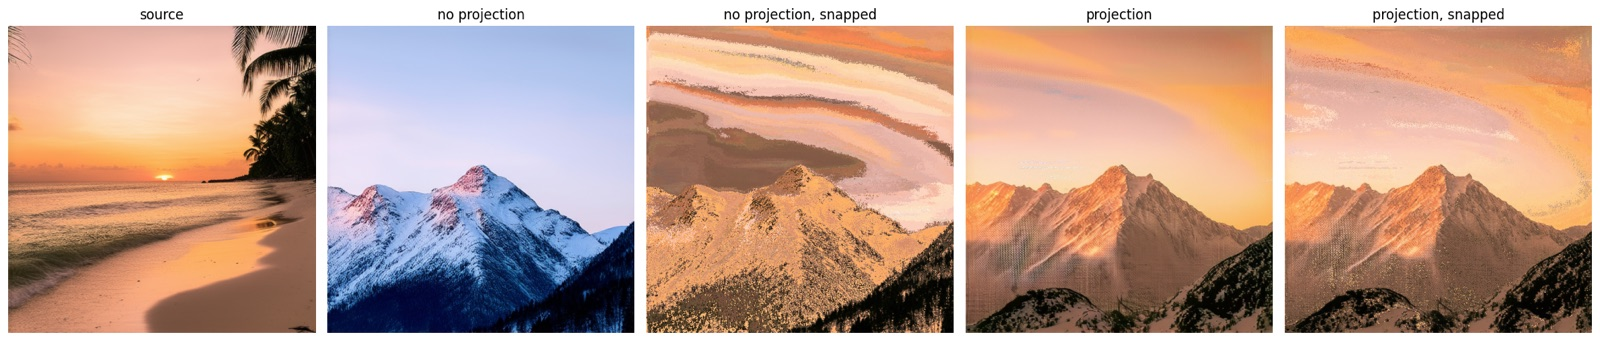
*Source: a tropical beach at sunset. Prompt: "a snowy mountain range at dawn". Left to right: the source; the model drawing freely; that drawing forced onto the source's pixels afterward; the model drawing with projection; that drawing snapped to the source's pixels. The last two panels and the first have exactly the same color histogram.*

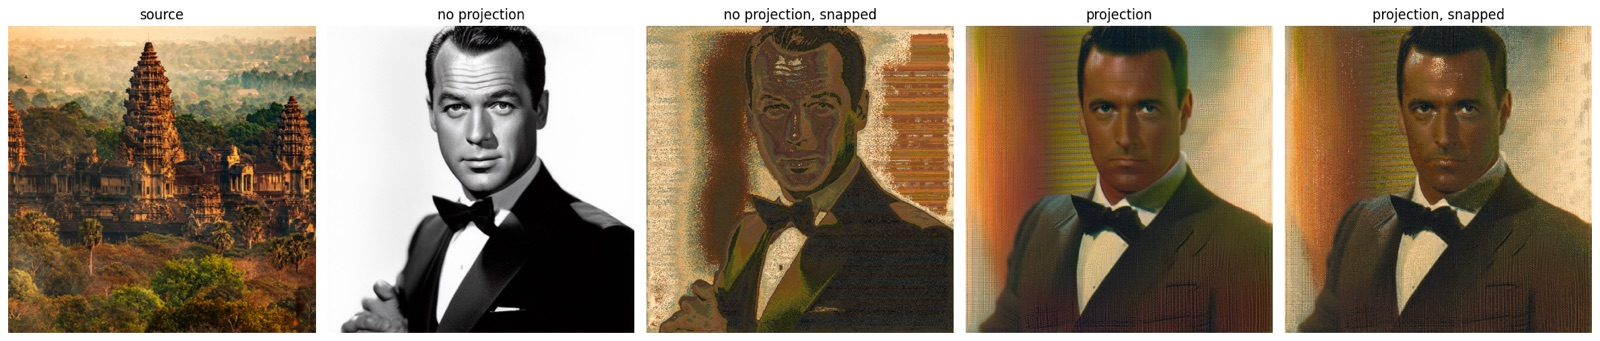
*Source: Angkor Wat at golden hour. Prompt: a classic spy-film portrait. Same five panels. The freely drawn image is black and white, which no amount of after-the-fact recoloring can rescue. With projection, the model relights the scene so it can absorb the temple's ochres and greens.*

## Problem statement

Let $s \in [0,1]^{N\times 3}$ be the source image's $N$ pixels and $c$ a text prompt. We want an image $y$ of the same size that depicts $c$ and has the **same joint RGB histogram** as $s$. Equal histograms at equal size mean $y$ is a permutation of $s$'s pixels:

$$y = P s, \qquad P \in \{0,1\}^{N\times N} \text{ a permutation matrix}.$$

So "generate an image with a given histogram" is really "choose an arrangement of $N$ fixed colors that a text-to-image model would find plausible for $c$". The feasible set is finite but astronomically large ($N!$ with $N = 262{,}144$), discrete and non-convex. It also lives in pixel space, while the generator works in a latent space.

## Method

### 1. Background: rectified flow sampling

Stable Diffusion 3.5 Medium [9] is a **rectified flow** model [7, 8]. A transformer [11] works in the latent space of an autoencoder [10]. Noise and data are joined by straight lines,

$$x_\sigma = (1-\sigma)\,x_0 + \sigma\,\varepsilon, \qquad \varepsilon \sim \mathcal N(0, I),$$

and the network predicts the velocity $v_\theta(x_\sigma, \sigma, c) \approx \varepsilon - x_0$. Sampling integrates from $\sigma=1$ (pure noise) to $\sigma=0$ (an image) with Euler steps $x \leftarrow x + (\sigma_{i+1}-\sigma_i)\,v$, using classifier-free guidance [12] ($v = v_u + w\,(v_c - v_u)$, $w=4.5$).

Because the path is a straight line, any intermediate state can be split exactly into the model's current guesses of where it's heading and where it came from:

$$\hat x_0 = x_\sigma - \sigma v, \qquad \hat\varepsilon = x_\sigma + (1-\sigma)\,v.$$

### 2. Projecting the prediction onto the source's colors

Every `project_every = 3` steps, while $0.15 < \sigma < 0.9$:

1. Decode $\hat x_0$ to pixels $\hat y = D(\hat x_0)$.
2. Move $\hat y$'s colors onto $s$'s color distribution with sliced optimal transport (below), giving $\tilde y$.
3. Encode back, $\tilde x_0 = E(\tilde y)$, and put it on the **same** noise trajectory: $x_\sigma \leftarrow (1-\sigma)\,\tilde x_0 + \sigma\,\hat\varepsilon$ and $v \leftarrow \hat\varepsilon - \tilde x_0$.

Reusing $\hat\varepsilon$ instead of drawing fresh noise keeps the sample's identity (composition, layout) stable across projections. This is the same idea as the noise-consistent resampling in RePaint [15] and SDEdit [16]. The window is a compromise. Above $\sigma\approx0.9$ the prediction $\hat x_0$ is a blurry average, so matching its colors is meaningless. Below $\sigma\approx0.15$ too few steps remain for the model to turn the recolored image back into a coherent one.

This is a heuristic instance of **projected sampling** [13]: alternate between the model's update and a projection onto a constraint set. It's applied to the clean-image prediction, as in posterior-sampling methods for inverse problems [14]. No gradients flow through the model, unlike D-Flow [17], which optimizes the initial noise through the whole sampler.

### 3. Sliced optimal transport

The ideal projection would be the optimal transport map from $\hat y$'s color cloud to $s$'s: the permutation minimizing $\sum_i \lVert \hat y_i - s_{\pi(i)} \rVert^2$ [5]. Solving it exactly costs about $O(N^3)$, which is out of reach at 262k points.

In **one** dimension, OT is just sorting. Pair the $k$-th smallest value of one set with the $k$-th smallest of the other, which is exactly classical histogram matching through the inverse CDF [4]. **Sliced OT** [2, 3] builds on that. Each iteration draws a random orthonormal basis $\Theta = [\theta_1, \theta_2, \theta_3]$ (QR of a Gaussian matrix), then for each axis replaces every pixel's coordinate $\langle \hat y_i, \theta_k \rangle$ with the source's coordinate of the same rank, and rotates back. After the iteration, the projections onto those three directions match exactly. Over 30 random bases, the full 3D distributions converge, since a distribution is determined by its 1D projections [6]. Each iteration is a descent step on the sliced Wasserstein distance [3].

Two properties make it a good projection here. Each 1D step is **monotone**, so color ordering (dark stays dark) and therefore image structure are preserved. And it costs $O(N\log N)$ per iteration, only milliseconds on a GPU. Matching R, G and B separately would not work: it matches the per-channel histograms but not the joint one. A 50/50 mix of yellow and black has the same R and G histograms as a 50/50 mix of red and green.

### 4. Exact snap

After sampling, $D(x_0)$ is close to the source distribution but not identical: sliced OT is approximate, and the VAE round trip is lossy. A final assignment makes it **exact**:

1. **Exact matches.** Each pixel gets an *occurrence id* (its 24-bit color plus its rank among pixels of that color). Ids present in both images are paired directly, at zero cost.
2. **Leftovers.** The remaining pixels on both sides are sorted along a **3D Hilbert curve** through RGB space [18, 19] and paired by rank. This is 1D optimal transport along a locality-preserving curve, a cheap $O(N \log N)$ stand-in for 3D OT. On test data it gave a lower average color error than a Morton (Z-order) curve.

Each source pixel is assigned exactly once, so `same_histogram` is true by construction. The average per-pixel change made by the snap measures how far the generation was from the constraint. With projection it is small. Without projection it is large, and the post-hoc snap produces the banded, posterized look in the third panels.

## What the results show

- **Projection changes *content*, not just color.** The model doesn't just tint the mountain orange. It relights it as alpenglow under a warm sky, a scene where those colors belong. In the portrait, the model gives up black and white and paints a warmly lit face against ochre and green. This is the main finding: a hard constraint on pixel statistics, imposed mid-trajectory, gets absorbed into the semantics of the image.
- **Post-hoc assignment fails in a characteristic way.** When the colors are forced on after the fact, smooth gradients become contour bands, because rank-pairing a smooth region against a differently shaped distribution quantizes it. Colors with no natural home end up in large, flat, wrong-colored regions.

## Limitations

- **Texture artifacts.** Projected outputs show a faint grid or cross-hatch texture. Each projection decodes and re-encodes through the VAE, and the encoder is being fed slightly off-distribution images. The errors build up across projections and the model doesn't fully clean them.
- **Heuristic, not principled.** Alternating projection gives no guarantee of sampling from the model's distribution restricted to the constraint set. It's a practical approximation, similar in spirit to [13, 15].
- **Approximate assignment.** The Hilbert snap is not the optimal 3D assignment. Some leftover pixels travel farther than they need to, which shows up as speckle.
- **Evaluation.** These are single seeds on a handful of image pairs, judged by eye. A proper study would report the snap displacement, prompt alignment (e.g. CLIP score) and image quality across many seeds and pairs, plus ablations of the window, frequency and number of sliced-OT iterations.
- **Reduced text encoder.** T5 is dropped to fit on a free GPU, which weakens prompt following on long or complicated prompts.

## Related work

- **Color histograms** as image descriptors go back to Swain & Ballard [1]. Their invariance to spatial arrangement is exactly what this notebook exploits.
- **Color transfer** recolors one image with another's palette, from Reinhard et al.'s per-channel statistics [4] to Pitié et al.'s iterative distribution transfer [2], which is the sliced OT used here. Those methods recolor a *fixed* image. Here the image content is free to change.
- **Histogram-conditioned generation**: HistoGAN [20] conditions a GAN on a target color histogram, a *soft* control learned during training. This notebook requires no training and enforces the histogram *exactly*.
- **Constrained sampling of diffusion and flow models**: projected diffusion [13], posterior sampling for inverse problems [14], inpainting by resampling [15], noise optimization through flows [17], and training-free guidance [21]. The constraint here is unusual: it is global (a distribution over all pixels), discrete (a permutation) and defined in pixel space, while the model works in a latent space.

## Future directions

- **Pixel-space or one-step models.** A pixel-space model removes the VAE round trip, the source of the texture artifacts. Alternatively, the projection could be done in latent space with a learned or linearized color map.
- **Gradient-based guidance instead of projection.** Add $\nabla$ of a differentiable sliced Wasserstein loss on $D(\hat x_0)$ to the velocity, as in [17, 21], and compare against hard projection.
- **Spatially aware assignment.** Replace the final snap with an OT cost that includes pixel position, $\lVert \Delta\text{color} \rVert^2 + \lambda \lVert \Delta\text{position} \rVert^2$, so leftover pixels travel to nearby places. Solve it with entropic OT (Sinkhorn) [5] on superpixels.
- **Other permutation constraints.** Same pixels in a different *order* is one constraint in a family: same tiles (generative photomosaics), same set of edges, or a shared palette across a whole video for temporal consistency.
- **Quantitative study.** Measure how the snap displacement and prompt alignment trade off as the source and the prompt get further apart in color. When does the model "give up" on the prompt?

## Bibliography

**Color histograms and color transfer**

- **[1]** M. J. Swain and D. H. Ballard. "Color Indexing." *International Journal of Computer Vision*, 7(1):11–32, 1991.
- **[2]** F. Pitié, A. Kokaram, and R. Dahyot. "N-Dimensional Probability Density Function Transfer and its Application to Colour Transfer." *ICCV*, 2005. Extended as "Automated Colour Grading Using Colour Distribution Transfer," *Computer Vision and Image Understanding*, 107(1–2):123–137, 2007.
- **[3]** J. Rabin, G. Peyré, J. Delon, and M. Bernot. "Wasserstein Barycenter and its Application to Texture Mixing." *Scale Space and Variational Methods in Computer Vision (SSVM)*, 2011. See also N. Bonneel, J. Rabin, G. Peyré, and H. Pfister, "Sliced and Radon Wasserstein Barycenters of Measures," *Journal of Mathematical Imaging and Vision*, 51(1):22–45, 2015.
- **[4]** E. Reinhard, M. Ashikhmin, B. Gooch, and P. Shirley. "Color Transfer between Images." *IEEE Computer Graphics and Applications*, 21(5):34–41, 2001.

**Optimal transport**

- **[5]** G. Peyré and M. Cuturi. "Computational Optimal Transport." *Foundations and Trends in Machine Learning*, 11(5–6):355–607, 2019. A free, readable textbook and the best single entry point.
- **[6]** H. Cramér and H. Wold. "Some Theorems on Distribution Functions." *Journal of the London Mathematical Society*, 11(4):290–294, 1936.

**Flow and diffusion models**

- **[7]** X. Liu, C. Gong, and Q. Liu. "Flow Straight and Fast: Learning to Generate and Transfer Data with Rectified Flow." *ICLR*, 2023.
- **[8]** Y. Lipman, R. T. Q. Chen, H. Ben-Hamu, M. Nickel, and M. Le. "Flow Matching for Generative Modeling." *ICLR*, 2023.
- **[9]** P. Esser, S. Kulal, A. Blattmann, et al. "Scaling Rectified Flow Transformers for High-Resolution Image Synthesis." *ICML*, 2024. (Stable Diffusion 3.)
- **[10]** R. Rombach, A. Blattmann, D. Lorenz, P. Esser, and B. Ommer. "High-Resolution Image Synthesis with Latent Diffusion Models." *CVPR*, 2022.
- **[11]** W. Peebles and S. Xie. "Scalable Diffusion Models with Transformers." *ICCV*, 2023.
- **[12]** J. Ho and T. Salimans. "Classifier-Free Diffusion Guidance." *NeurIPS Workshop on Deep Generative Models*, 2021. arXiv:2207.12598.

Background: J. Ho, A. Jain, and P. Abbeel, "Denoising Diffusion Probabilistic Models," *NeurIPS*, 2020. Y. Song et al., "Score-Based Generative Modeling through Stochastic Differential Equations," *ICLR*, 2021.

**Constrained and guided sampling**

- **[13]** J. K. Christopher, S. Baek, and F. Fioretto. "Constrained Synthesis with Projected Diffusion Models." *NeurIPS*, 2024.
- **[14]** H. Chung, J. Kim, M. T. Mccann, M. L. Klasky, and J. C. Ye. "Diffusion Posterior Sampling for General Noisy Inverse Problems." *ICLR*, 2023.
- **[15]** A. Lugmayr, M. Danelljan, A. Romero, F. Yu, R. Timofte, and L. Van Gool. "RePaint: Inpainting using Denoising Diffusion Probabilistic Models." *CVPR*, 2022.
- **[16]** C. Meng, Y. He, Y. Song, J. Song, J. Wu, J.-Y. Zhu, and S. Ermon. "SDEdit: Guided Image Synthesis and Editing with Stochastic Differential Equations." *ICLR*, 2022.
- **[17]** H. Ben-Hamu, O. Puny, I. Gat, B. Karrer, U. Singer, and Y. Lipman. "D-Flow: Differentiating through Flows for Controlled Generation." *ICML*, 2024.
- **[21]** A. Bansal, H.-M. Chu, A. Schwarzschild, S. Sengupta, M. Goldblum, J. Geiping, and T. Goldstein. "Universal Guidance for Diffusion Models." *ICLR*, 2024.

**Histogram-controlled generation**

- **[20]** M. Afifi, M. A. Brubaker, and M. S. Brown. "HistoGAN: Controlling Colors of GAN-Generated and Real Images via Color Histograms." *CVPR*, 2021.

**Space-filling curves**

- **[18]** D. Hilbert. "Über die stetige Abbildung einer Linie auf ein Flächenstück." *Mathematische Annalen*, 38:459–460, 1891.
- **[19]** J. Skilling. "Programming the Hilbert Curve." *AIP Conference Proceedings*, 707:381–387, 2004.

**Course**

- UC Berkeley CS180, *Intro to Computer Vision and Computational Photography*, Fall 2026. https://cal-cs180.github.io/fa26/